In [1]:
import matplotlib.pyplot as plt
import numpy as np
import numpy.ma as ma
import pandas as pd
import scipy as sp
import seaborn as sns
from scipy import stats
from scipy.stats import bootstrap
from scipy.optimize import curve_fit
from scipy.optimize import fsolve
from scipy.optimize import approx_fprime
from sklearn.metrics import r2_score
import statsmodels.api as sm
from statsmodels.formula.api import ols

# # Suppress warnings (temporary)
# warnings.simplefilter(action='ignore', category=FutureWarning)
# warnings.simplefilter(action='ignore', category=DeprecationWarning)

# Set some defaults
# custom_cmap = LinearSegmentedColormap.from_list("custom", ["#F1F744", "#D49BFF"])
sns.set_theme(context="paper", font_scale=1.2)
sns.set_style("ticks")
plt.rcParams["mathtext.default"] = "regular"
plt.rc("axes.spines", top=False, right=False)

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [2]:
df = pd.read_csv("data/adapt_FINAL.csv")
df_sdt = pd.read_csv("data/sdt_FINAL.csv")
df["adaptation"] = np.nan
df["total error"] = np.nan

# change perturbation detection column name to something shorter
df_sdt.rename(columns={'perturbation_responses': 'det'}, inplace=True)

df_sdt.reset_index(drop=True, inplace=True)
df_sdt.columns

Index(['si', 'SN', 'id', 'tester', 'TN', 'move_cycle', 'hX', 'hY', 'rot_hX',
       'rot_hY', 'rotation', 'tgt_jump', 'hand_max_dist', 'radvelmax', 'tgtX',
       'tgtY', 'rot_hand_theta', 'theta_maxradv', 'raw_ep_hand_ang', 'tgt_ang',
       'tgt_dist', 'fbi', 'MT', 'RT', 'ST', 'det'],
      dtype='object')

In [3]:
# Outlier removal
z_thresh = 3.5

# z-score hand angle data
df["theta_maxradv_z"] = df.groupby("SN")["theta_maxradv"].transform(stats.zscore)

# z-score movement extent data
df["hand_max_dist_z"] = df.groupby("SN")["hand_max_dist"].transform(stats.zscore)

# Create outlier column for hand angle data (classified outlier based on angle and distance)
df["theta_maxradv_outlier"] = (
    (np.abs(df["theta_maxradv_z"]) > z_thresh) 
    | (np.abs(df["hand_max_dist_z"]) > z_thresh) 
)

# Create outlier column for movement extent data (classified outlier based on angle and distance)
df["hand_max_dist_outlier"] = (
    (np.abs(df["theta_maxradv_z"]) > z_thresh) 
    | (np.abs(df["hand_max_dist_z"]) > z_thresh) 
)

# Calculate within-subject mean of hand angle using non-outlier trials only
df["theta_maxradv_mean"] = (
    df[(np.abs(df["theta_maxradv_z"]) <= z_thresh) & (np.abs(df["hand_max_dist_z"]) <= z_thresh)]
    .groupby("SN")["theta_maxradv"].transform(np.mean)
)

# Calculate within-subject mean of movement extent using non-outlier trials only
df["hand_max_dist_mean"] = (
    df[(np.abs(df["theta_maxradv_z"]) <= z_thresh) & (np.abs(df["hand_max_dist_z"]) <= z_thresh)]
    .groupby("SN")["hand_max_dist"].transform(np.mean)
)

# Replace outliers with NaNs
df["theta_maxradv_clean"] = np.where(
    (np.abs(df["theta_maxradv_z"]) > z_thresh) | (np.abs(df["hand_max_dist_z"]) > z_thresh),
    np.nan,
    df["theta_maxradv"])

df["hand_max_dist_clean"] = np.where(
    (np.abs(df["theta_maxradv_z"]) > z_thresh) | (np.abs(df["hand_max_dist_z"]) > z_thresh),
    np.nan,
    df["hand_max_dist"])

# Create col that replaces outliers with within-subject mean values (may not use)
df["theta_maxradv_mean"] = df.groupby("SN")["theta_maxradv_mean"].transform(lambda x: x.fillna(np.nanmean(x)))


/var/folders/42/fy648srd41l966jbjlswhljc0000gr/T/ipykernel_48444/2253970377.py:25: FutureWarning: The provided callable <function mean at 0x11161e340> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  .groupby("SN")["theta_maxradv"].transform(np.mean)
/var/folders/42/fy648srd41l966jbjlswhljc0000gr/T/ipykernel_48444/2253970377.py:31: FutureWarning: The provided callable <function mean at 0x11161e340> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  .groupby("SN")["hand_max_dist"].transform(np.mean)


In [4]:
def compute_betas(df: pd.DataFrame, rot_range: int, bivariate=True):

    df_filt = df[df["rotation"].between(-rot_range, rot_range, inclusive='both')]

    # df_filt = df_filt[np.abs(df_filt["adaptation"]) < 15]

    # Prepare data for regression
    data = pd.DataFrame({
        'ege': df_filt["rotation"], 
        'ige': df_filt["theta_maxradv_clean"],
        'adapt': df_filt["adaptation"]
    })
    
    if bivariate:
        # Run OLS regression 
        model = ols("adapt ~ ege + ige - 1", data).fit()
        beta_ege = model.params.get("ege", np.nan)
        beta_ige = model.params.get("ige", np.nan)
        return beta_ege, beta_ige
    else:
        model = ols("adapt ~ ege", data).fit()
        beta_ege = model.params.get("ege", np.nan)
        return beta_ege

    
def piecewise_linear_2bp(x, a, b, c, e, x0, x1):
    '''
    x: input data
    a: slope from -10 to -6
    b: bias from -10 to -6
    c: slope from -6 to +6
    d: bias from -6 to +6
    e: slope from +6 to +10
    f: bias from +6 to +10
    '''
    # Ensure continuity across both breakpoints
    d = a * x0 + b - c * x0
    f = c * x1 + d - e * x1
    return np.piecewise(
        x,
        [x < x0, (x >= x0) & (x < x1), x >= x1],
        [lambda x: a * x + b,  
        lambda x: c * x + d,
        lambda x: e * x + f]
    )
    
def fit_piecewise_with_ci(df, subject_id, xcol="rotation", ycol="adaptation", 
                          bp1=6, bp2=-6, n_points=300, alpha=0.05):

    x = np.array(df[xcol])
    y = np.array(df[ycol])

    # Remove NaN or Inf
    mask = ~np.isnan(x) & ~np.isnan(y)
    x_clean, y_clean = x[mask], y[mask]

    # Fit
    popt, pcov = curve_fit(
        lambda x, a, b, c, e: piecewise_linear_2bp(x, a, b, c, e, x0=bp2, x1=bp1),
        x_clean, y_clean
    )

    # Fit line
    x_fit = np.linspace(min(x_clean), max(x_clean), n_points)
    y_fit = piecewise_linear_2bp(x_fit, *popt, x0=bp2, x1=bp1)

    # Jacobian for variance propagation
    eps = np.sqrt(np.finfo(float).eps)
    jac = np.array([
        approx_fprime(popt, 
                      lambda p: piecewise_linear_2bp(np.array([xx]), *p, x0=bp2, x1=bp1)[0], 
                      eps)
        for xx in x_fit
    ])
    var_pred = np.sum(jac @ pcov * jac, axis=1)
    std_pred = np.sqrt(var_pred)

    # Confidence intervals
    z = 1.96  # ~95% for large df
    ci_upper = y_fit + z * std_pred
    ci_lower = y_fit - z * std_pred

    return x_fit, y_fit, ci_lower, ci_upper, popt, pcov

In [5]:
# Count number of outliers per participant
num_outliers = df.groupby("SN")["theta_maxradv_outlier"].sum()
print(num_outliers)

# Print proportion of trials removed
print(num_outliers / df["TN"].max())

SN
1     24
2     12
3     16
4      4
5     11
6      9
7      8
8     10
9     20
10    12
11     9
12     8
13     5
14    12
15    11
16     6
Name: theta_maxradv_outlier, dtype: int64
SN
1     0.014634
2     0.007317
3     0.009756
4     0.002439
5     0.006707
6     0.005488
7     0.004878
8     0.006098
9     0.012195
10    0.007317
11    0.005488
12    0.004878
13    0.003049
14    0.007317
15    0.006707
16    0.003659
Name: theta_maxradv_outlier, dtype: float64


In [6]:
# Compute baseline motor variability based on last 50 baseline trials 
df["motor_sd"] = (
    df[(df["TN"] >= 51) & (df["TN"] <= 100)].groupby("SN")["theta_maxradv_clean"].transform(np.nanstd))
df.head(10)

# Create col that replaces outliers with within-subject mean values (may not use)
df["motor_sd"] = df.groupby("SN")["motor_sd"].transform(lambda x: x.fillna(np.nanmean(x)))

/var/folders/42/fy648srd41l966jbjlswhljc0000gr/T/ipykernel_48444/2836252095.py:3: FutureWarning: The provided callable <function nanstd at 0x1117ac180> is currently using SeriesGroupBy.std. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "std" instead.
  df[(df["TN"] >= 51) & (df["TN"] <= 100)].groupby("SN")["theta_maxradv_clean"].transform(np.nanstd))


In [7]:
df[((df["TN"] >= 50) & (df["TN"] < 100))].groupby("SN")["theta_maxradv_clean"].transform(np.std)

/var/folders/42/fy648srd41l966jbjlswhljc0000gr/T/ipykernel_48444/3362528773.py:1: FutureWarning: The provided callable <function std at 0x11161e480> is currently using SeriesGroupBy.std. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "std" instead.
  df[((df["TN"] >= 50) & (df["TN"] < 100))].groupby("SN")["theta_maxradv_clean"].transform(np.std)


49       2.245266
50       2.245266
51       2.245266
52       2.245266
53       2.245266
           ...   
24694    2.628834
24695    2.628834
24696    2.628834
24697    2.628834
24698    2.628834
Name: theta_maxradv_clean, Length: 800, dtype: float64

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
The slope for EGE is -0.285; IGE is -0.158.


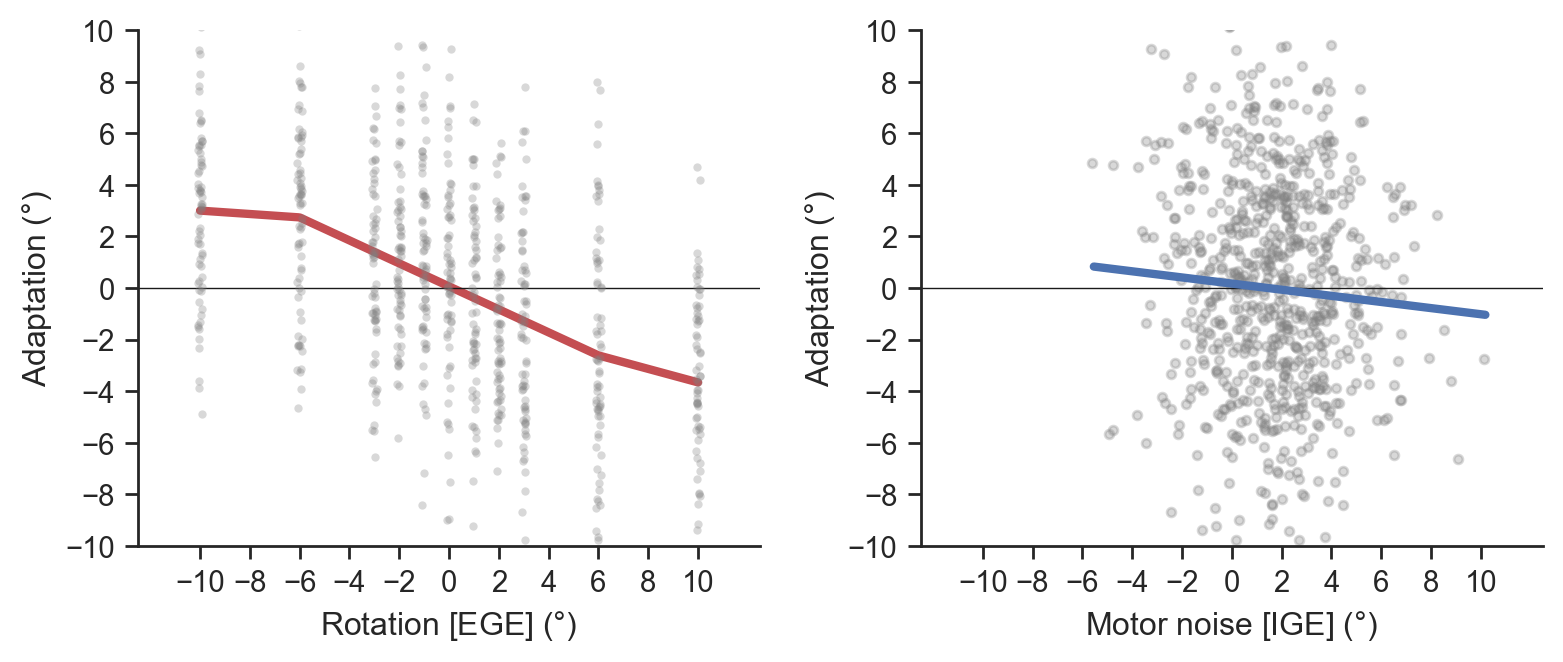

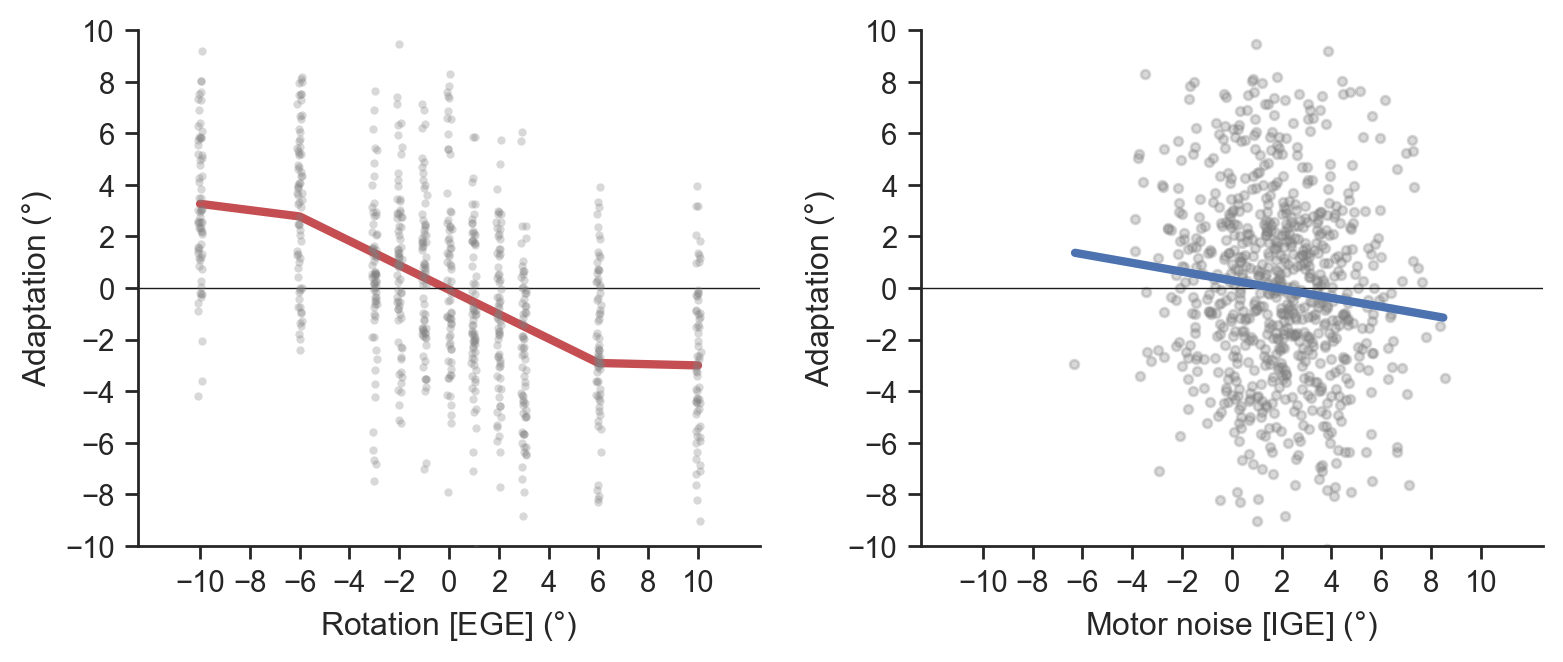

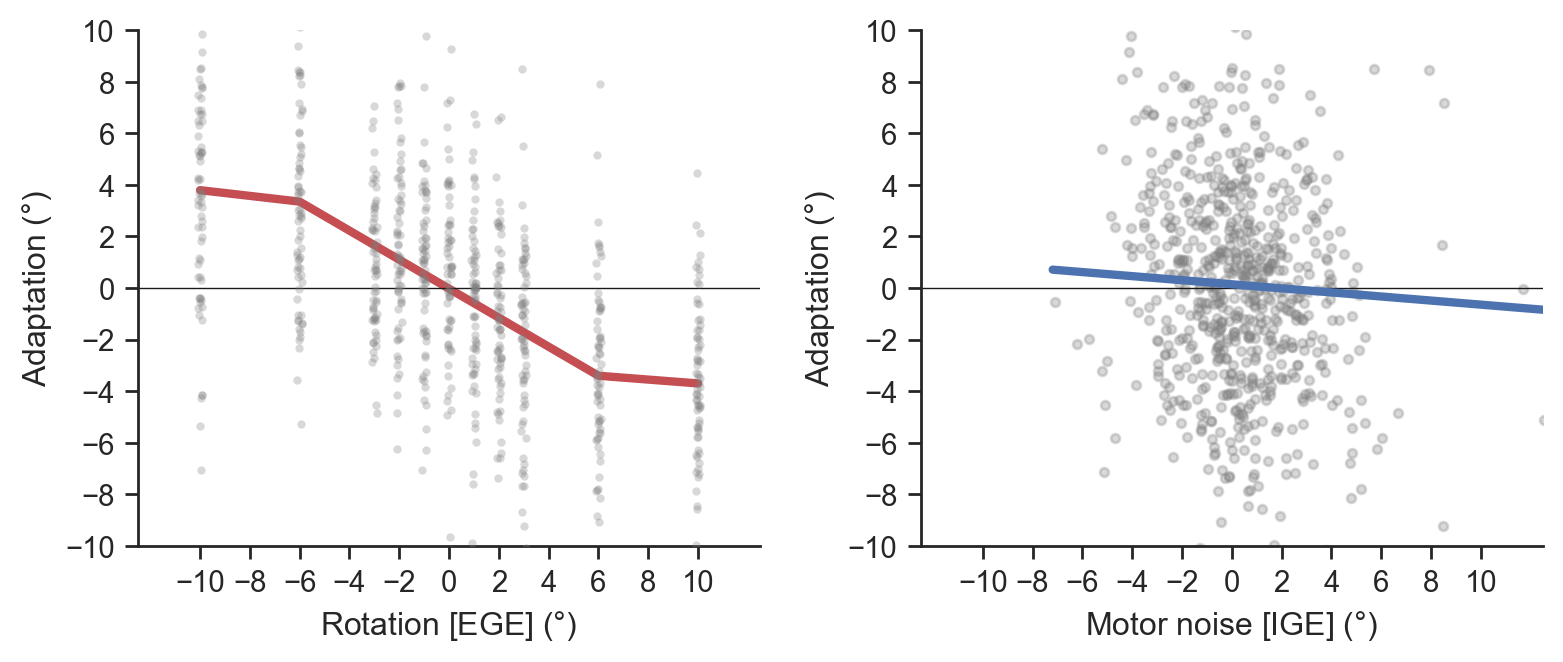

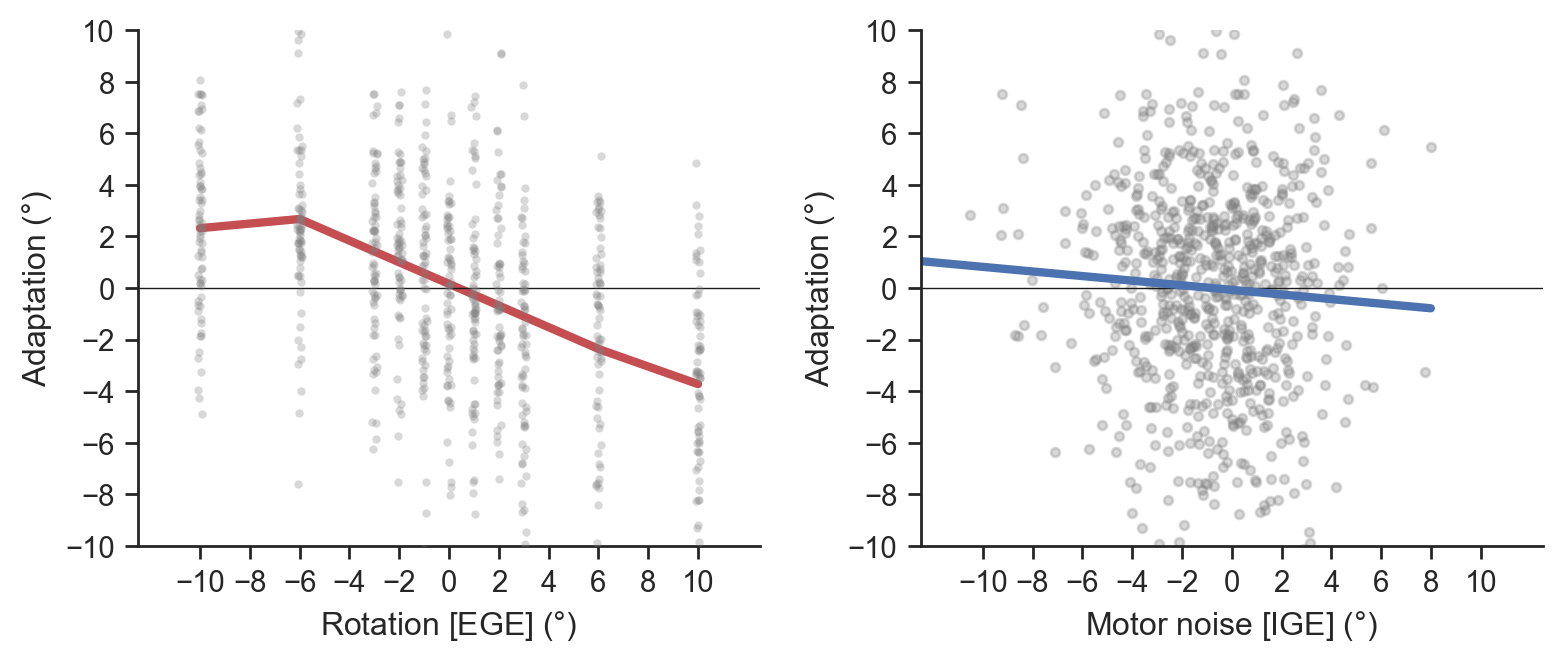

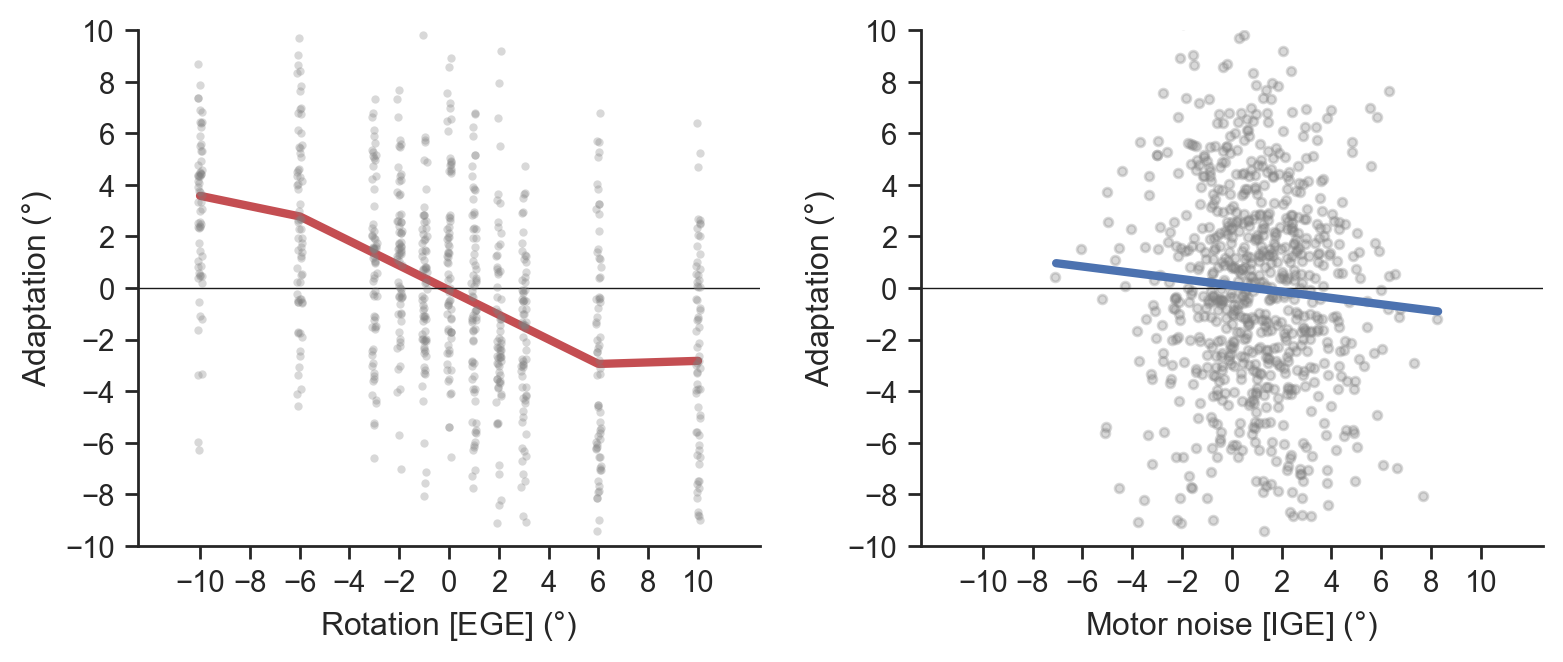

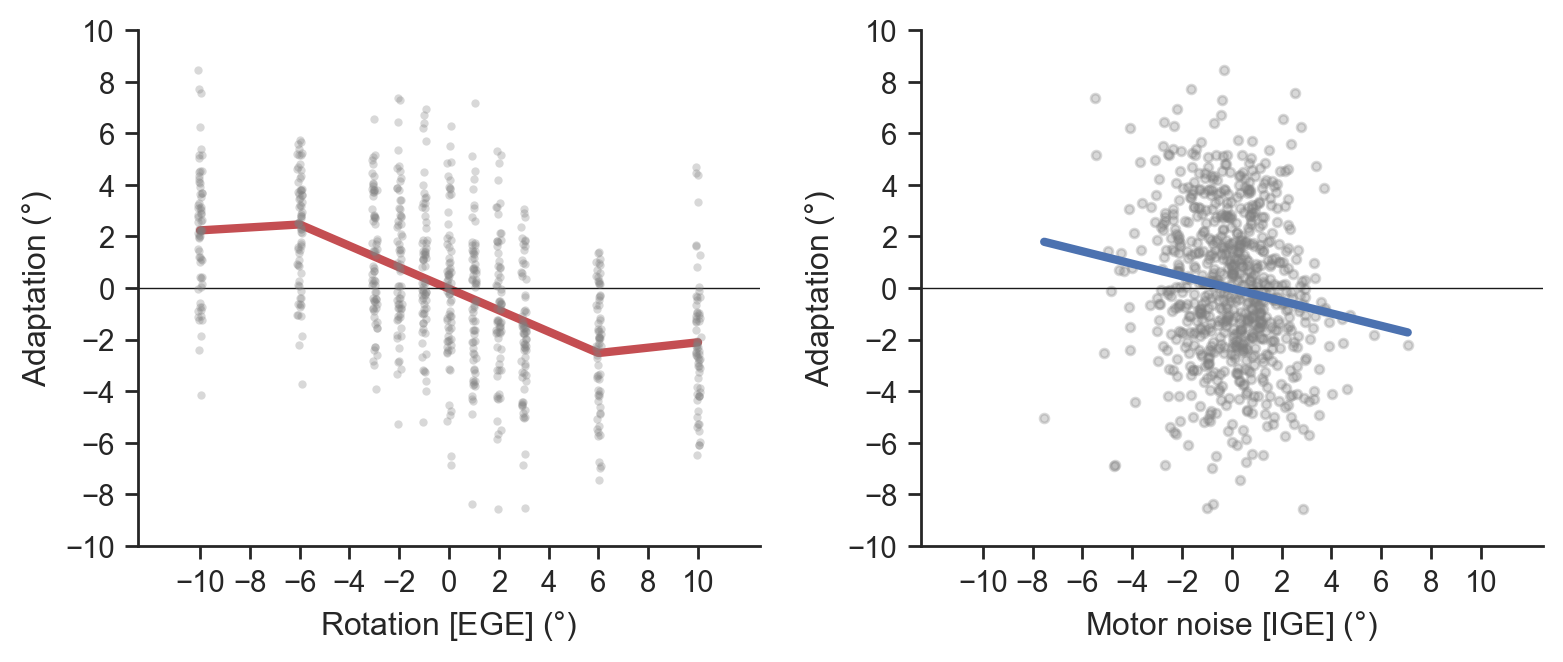

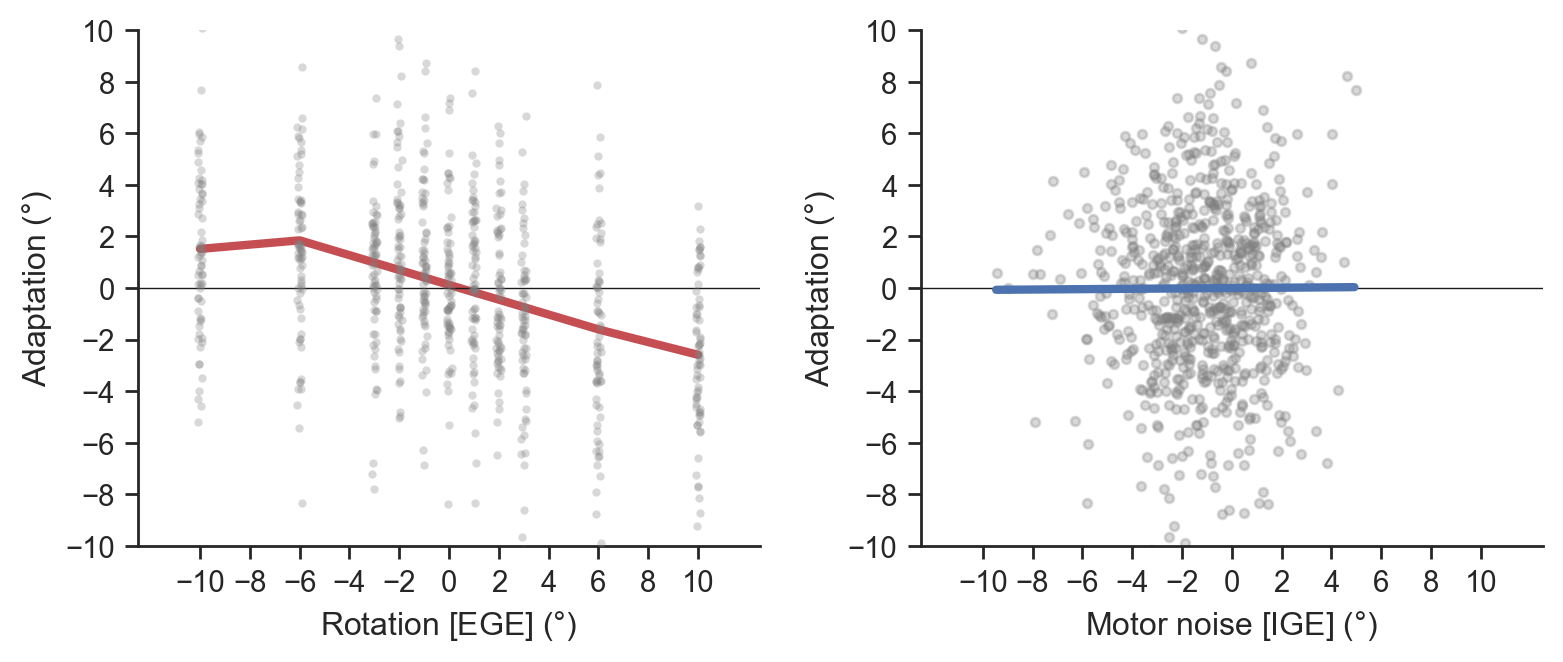

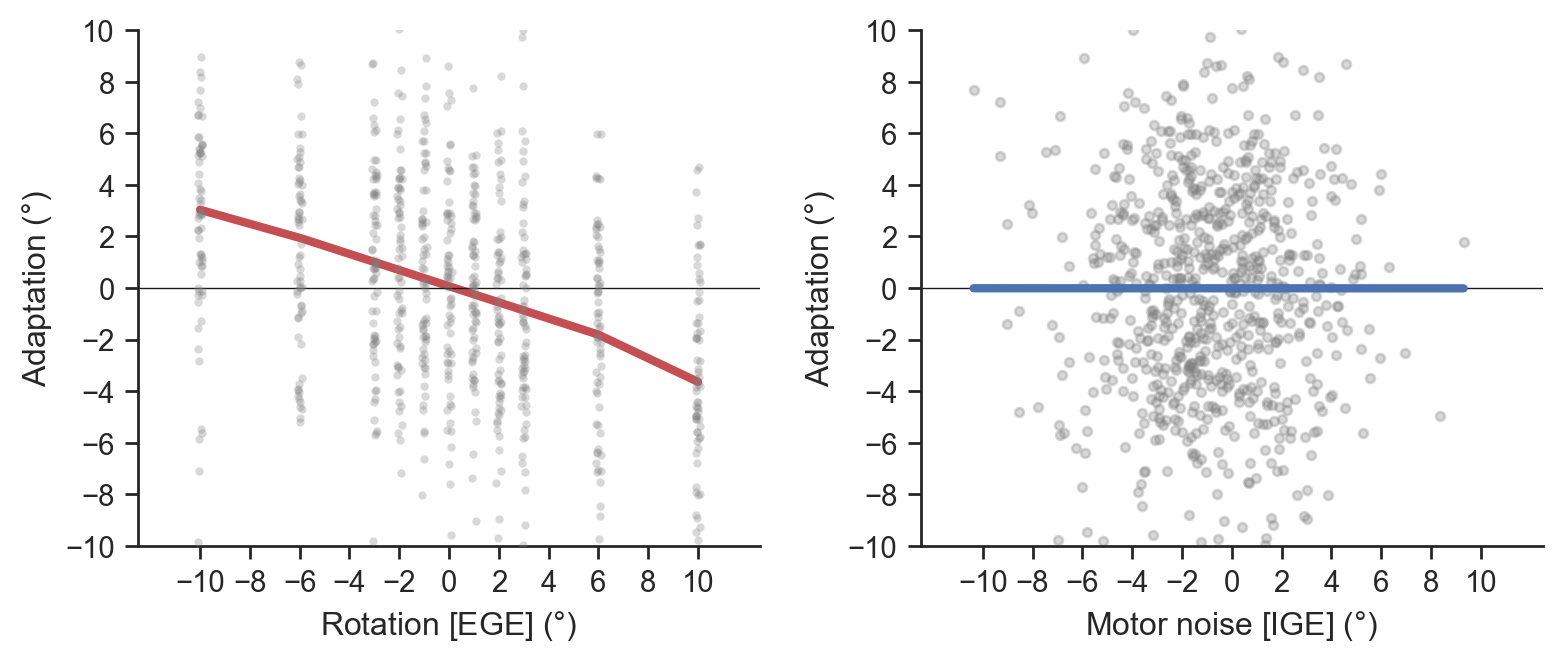

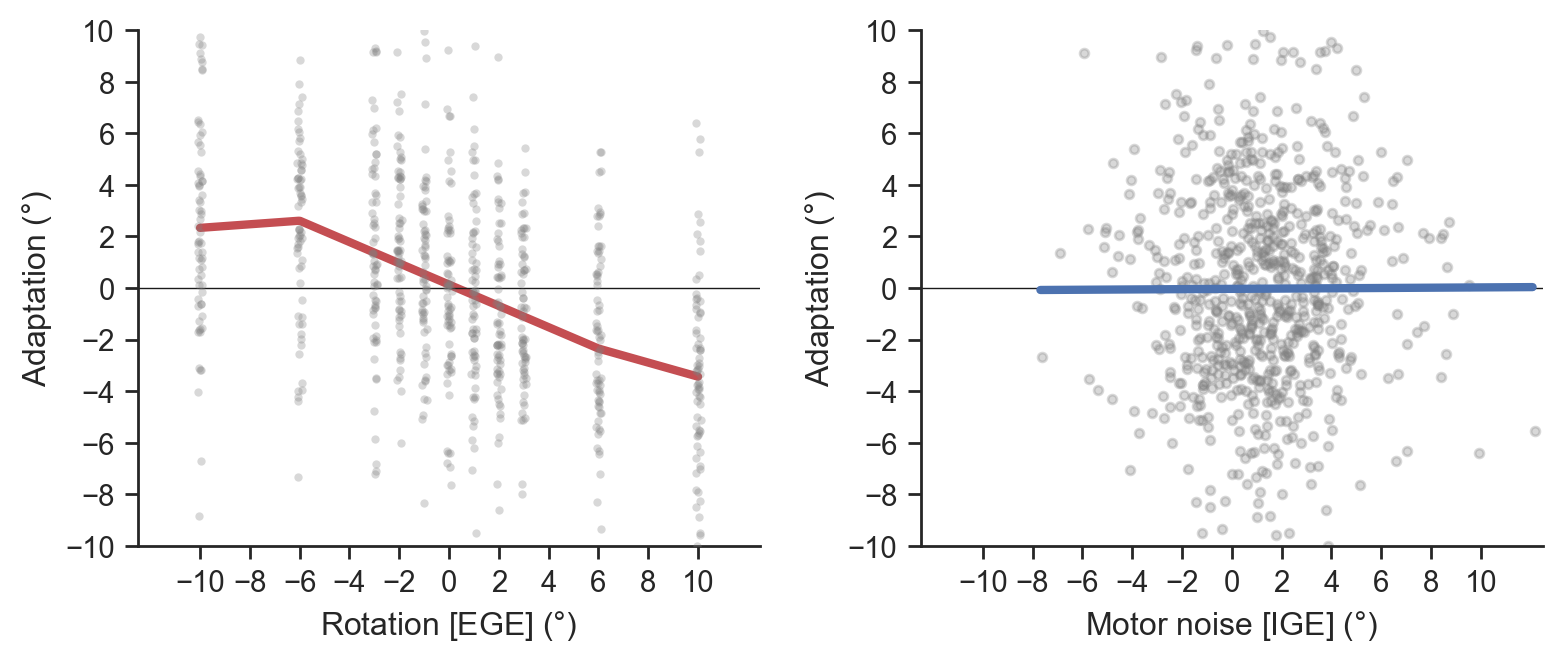

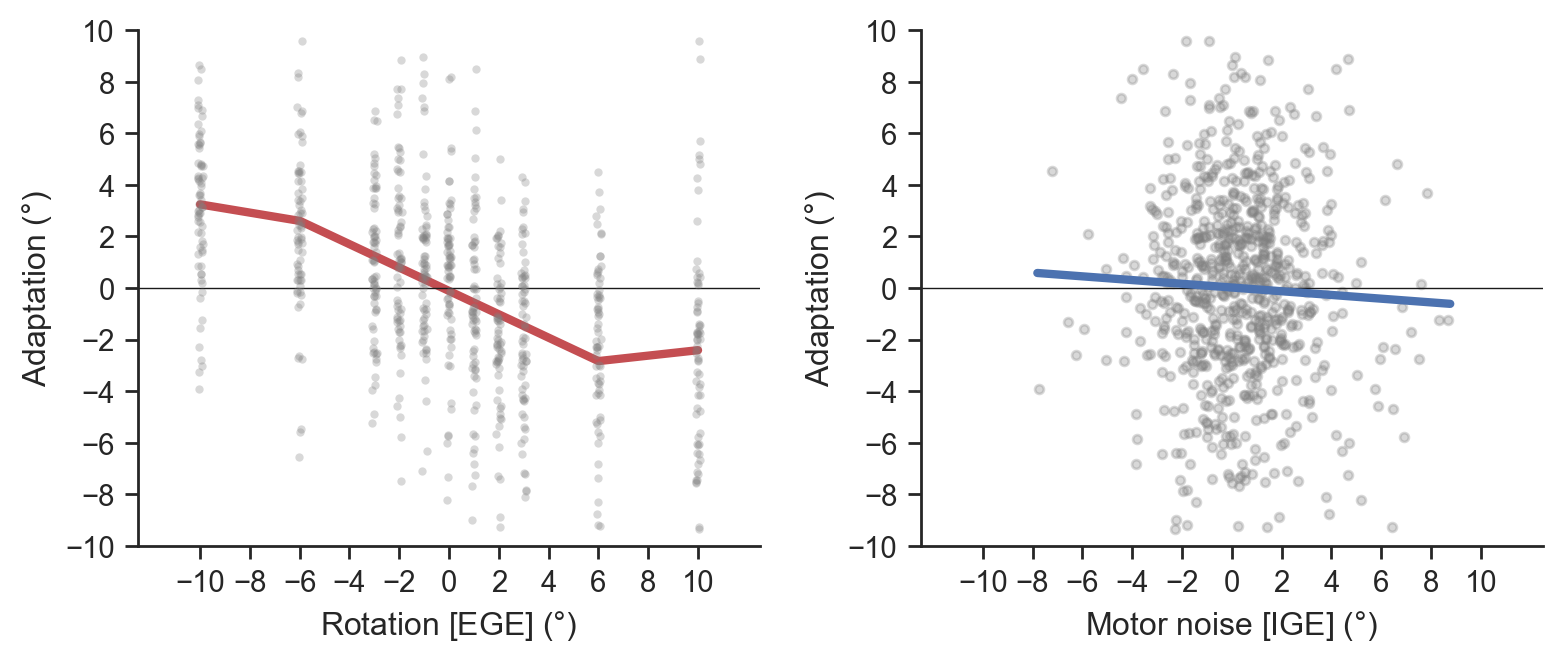

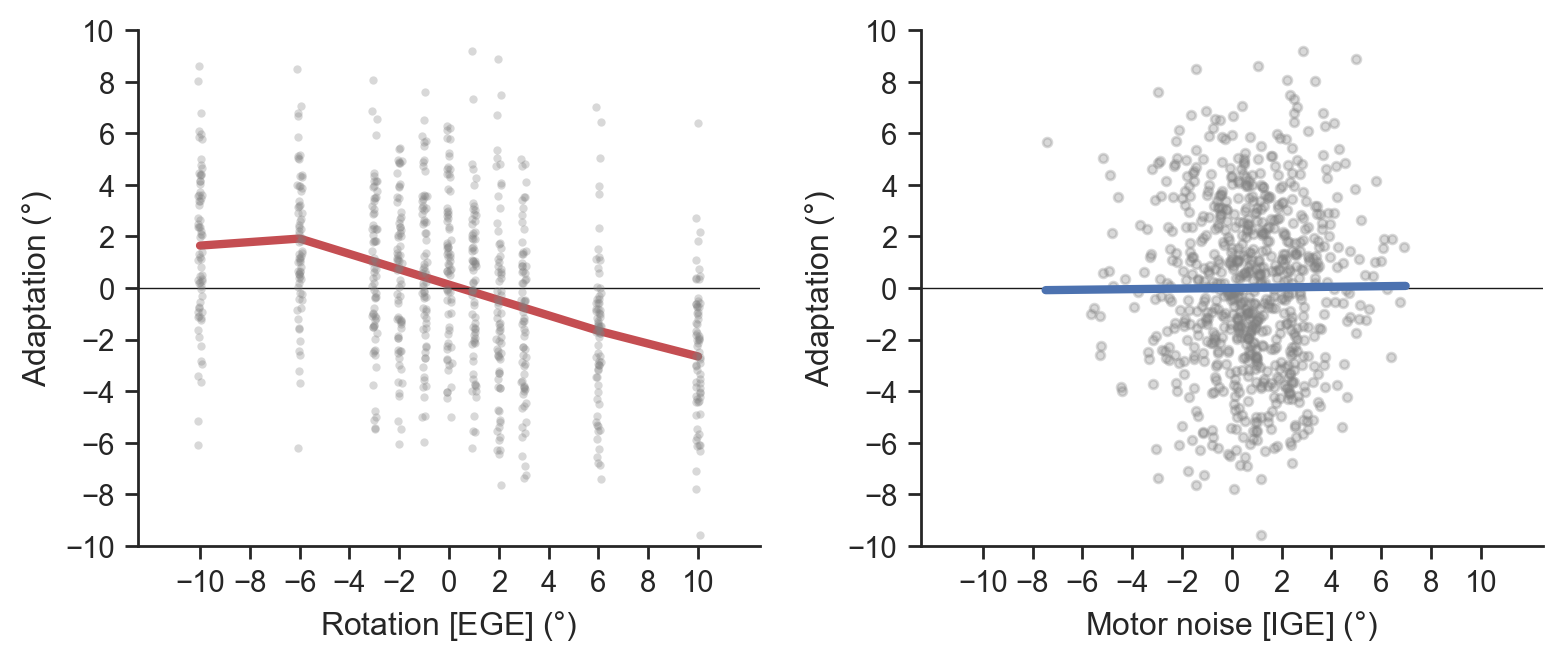

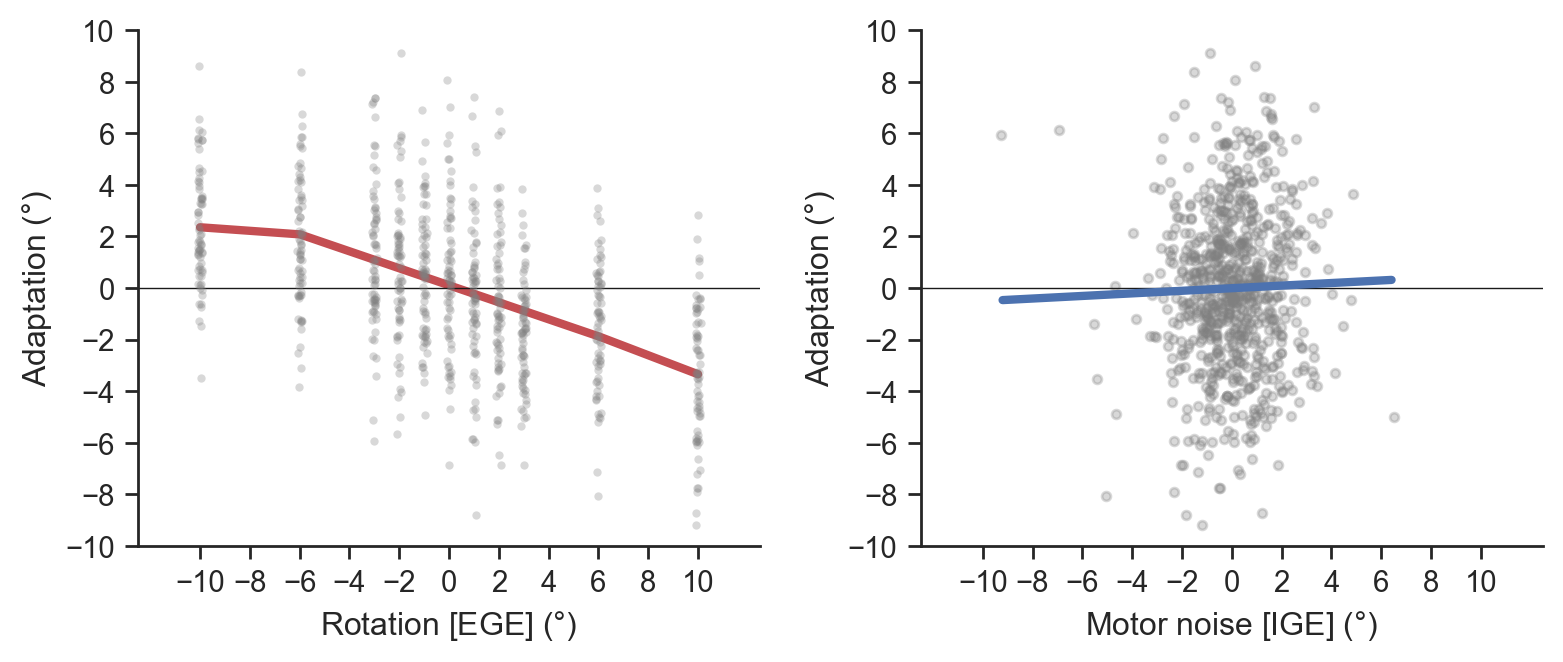

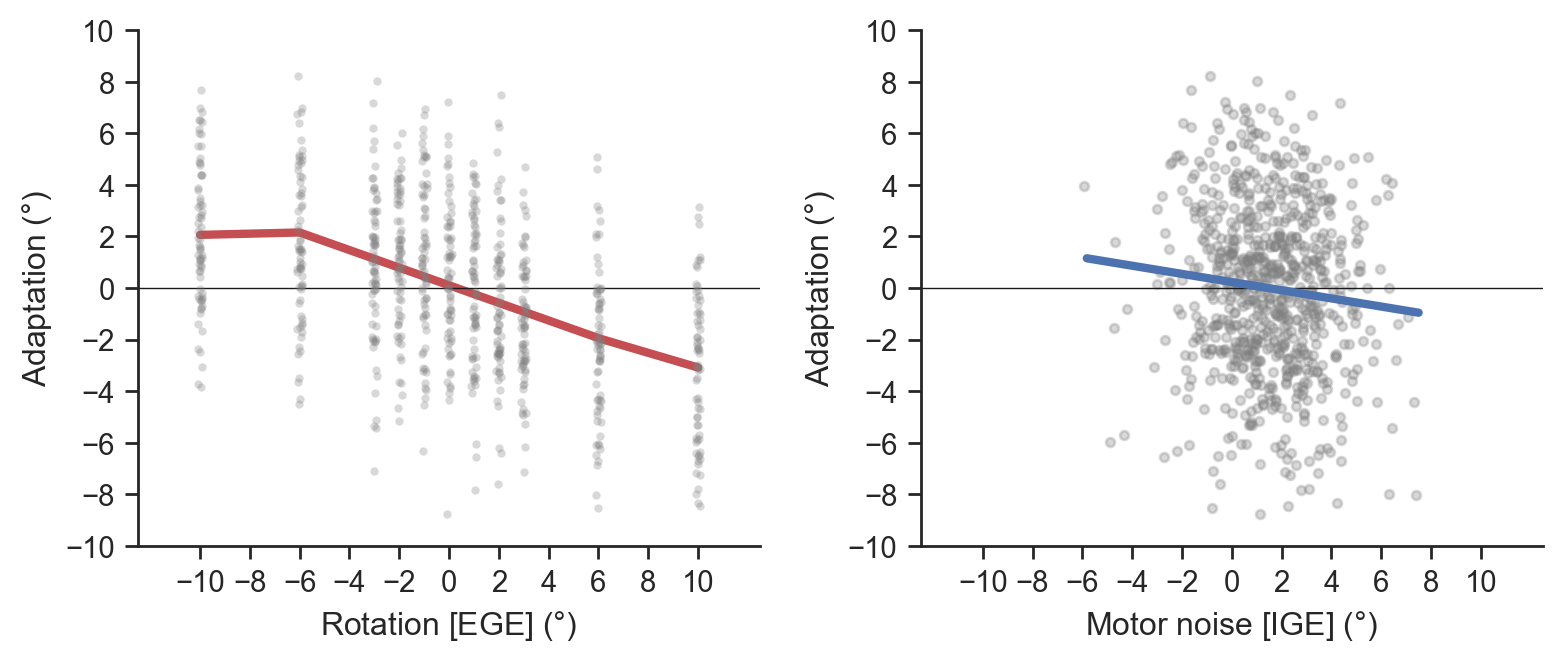

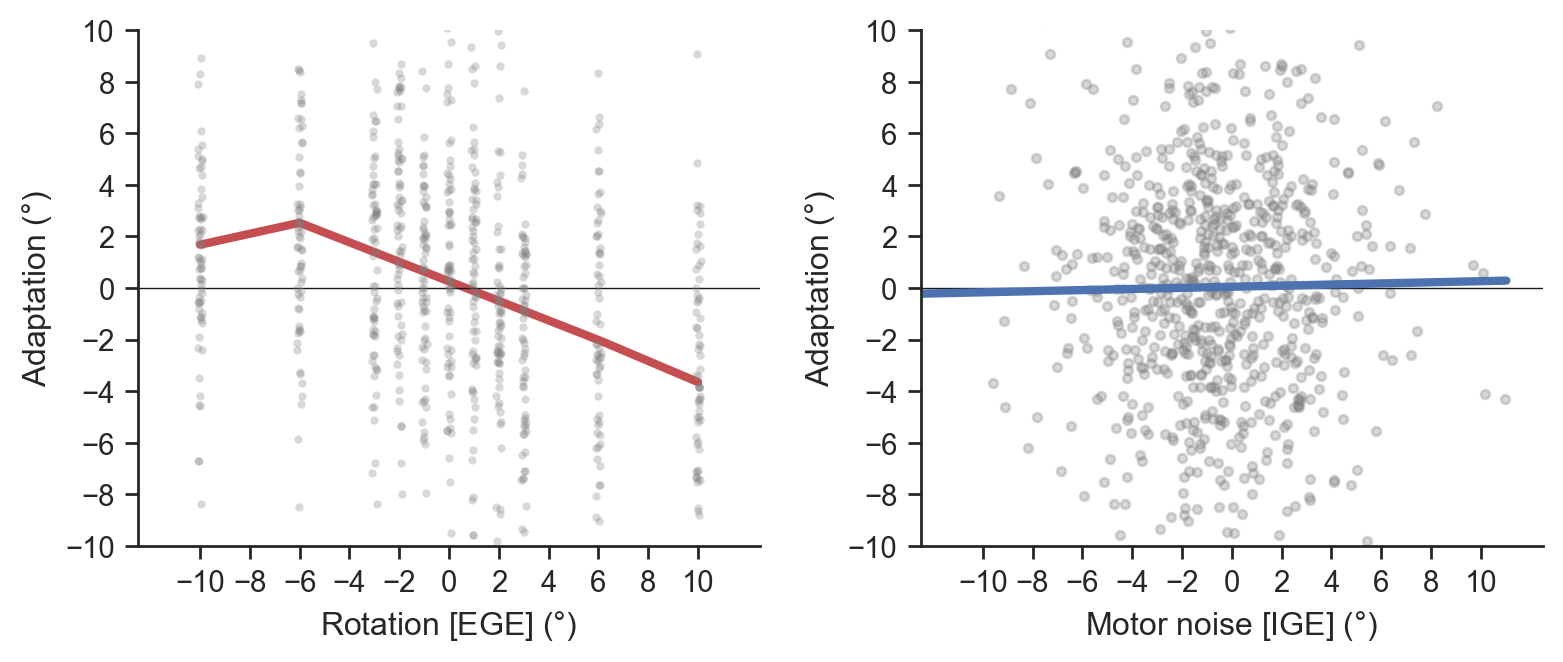

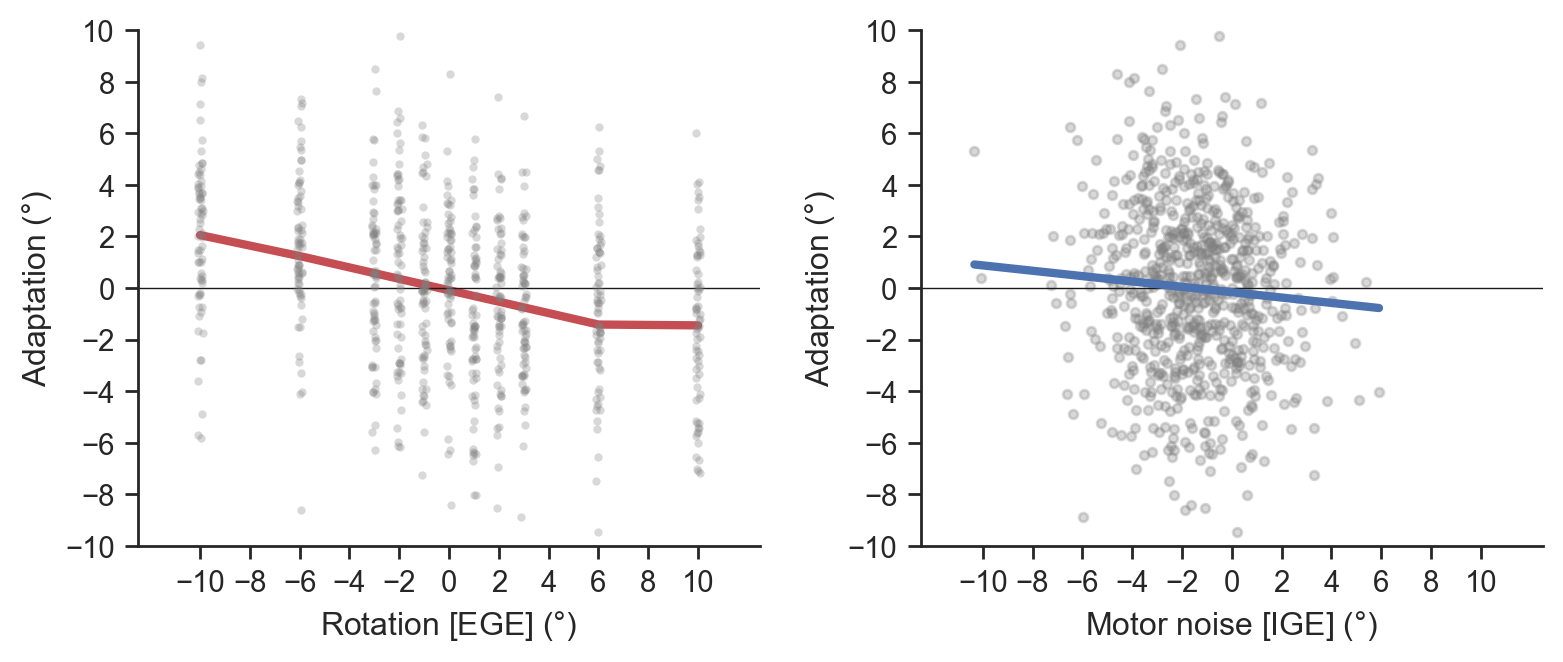

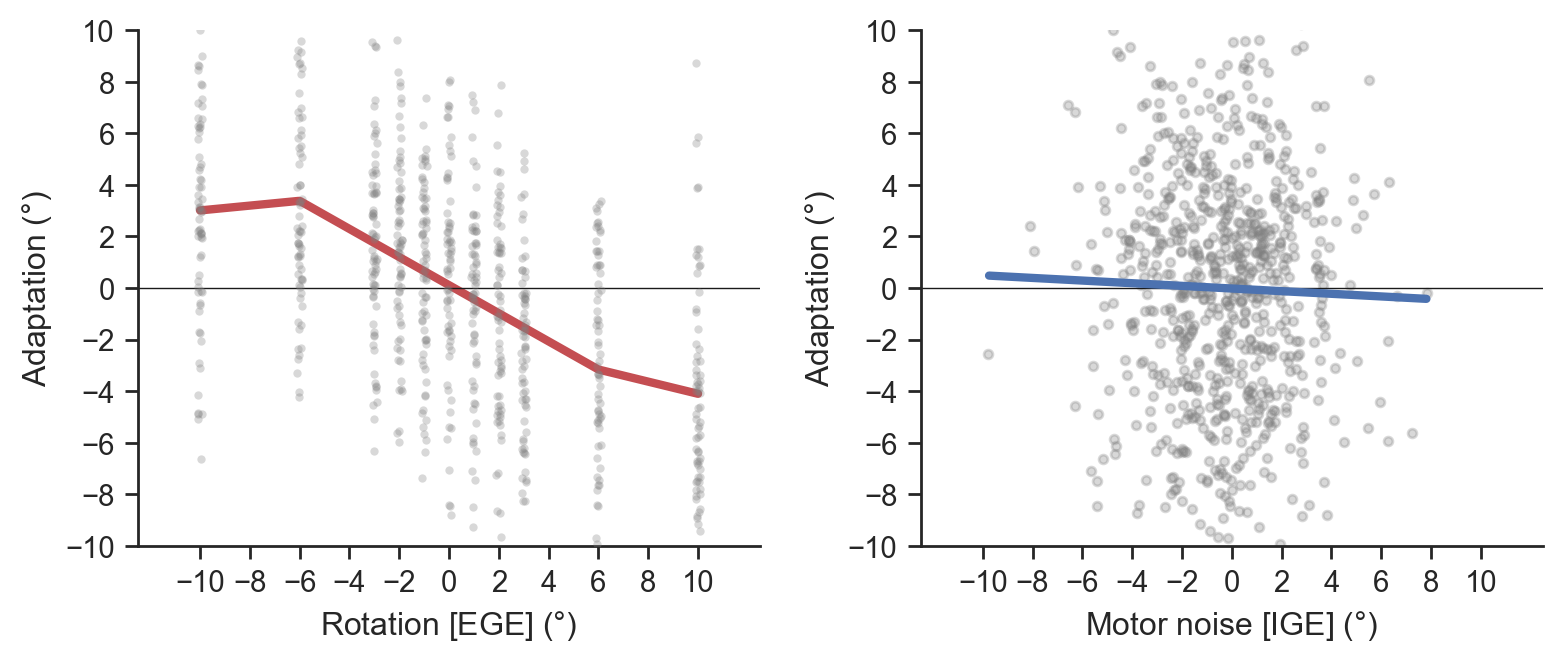

In [8]:
# Choose whether to visualize all data or only adaptation trials preceded by no fb
truncate = False

adapt_rotation = pd.DataFrame()
vmr_all = pd.DataFrame()
sigma_motor_bsl = []
sigma_motor_train = []
sigma_v_train = []
beta_rotation_ege = np.zeros(len(df["id"].unique()))
beta_rotation_ige = np.zeros(len(df["id"].unique()))
beta_ege_1ege_bi = np.zeros(len(df["id"].unique()))
beta_ige_1ege_bi = np.zeros(len(df["id"].unique()))
beta_ege_1ege_uni = np.zeros(len(df["id"].unique()))
beta_ige_1ige_uni = np.zeros(len(df["id"].unique()))
beta_ege_6ege_uni = np.zeros(len(df["id"].unique()))
beta_ige_6ege_uni = np.zeros(len(df["id"].unique()))
beta_ege_6ege_bi = np.zeros(len(df["id"].unique()))
beta_ige_6ege_bi = np.zeros(len(df["id"].unique()))
beta_ege_all_uni = np.zeros(len(df["id"].unique()))
beta_ext = np.zeros(len(df["id"].unique()))
n_1ige = np.zeros(len(df["id"].unique()))
# Create a new variable for movement extent errors (Change this)
df["extent_err"] = df["hand_max_dist_clean"] - 90

for k, s in enumerate(df["id"].unique()):
    # Create subject-specific data frame
    subj = df[df["id"] == s].reset_index(drop=True)
    
    # Calculate baseline variability
    sigma_motor_bsl.append(subj.loc[50:100, "theta_maxradv_clean"].std())
    
    # Create truncated data frame without baseline trials
    training_start = 100
    subj_train = subj.iloc[training_start - 1:, :].reset_index(drop=True)
    pert_idx = np.arange(1, len(subj_train), 2)
    
    # Loop through trials to get adaptation index
    for i in np.arange(1, len(subj_train), 2):
        subj_train.loc[i, "adaptation"] = subj_train.loc[i + 1, "theta_maxradv_clean"] - subj_train.loc[i - 1, "theta_maxradv_clean"] 
        subj_train.loc[i, "total error"] = subj_train.loc[i, "theta_maxradv_clean"] + subj_train.loc[i, "rotation"]
        # Measure IGE adaptation to movement extent errors
        subj_train.loc[i, "adaptation_ext"] = subj_train.loc[i + 1, "extent_err"] - subj_train.loc[i - 1, "extent_err"]
    
    # Calculate motor and vis fb variability during training
    sigma_motor_train.append(subj_train["theta_maxradv_clean"].std())
    vis_fb_idx = subj_train["fbi"] == 1
    sigma_v_train.append(subj_train.loc[vis_fb_idx, "total error"].std())

    # Dataframes for perturbation trials only (trim null trials)
    subj_adapt = subj_train.loc[pert_idx, :].reset_index()
    
    # Pick out trials preceded by no-feedback null trial w/boolean mask
    nofb_idx = np.zeros(len(subj_train), dtype=bool)
    nofb_idx[1:] = subj_train.loc[0:len(subj_train) - 2, "fbi"] == 0  # .loc slicing includes start and stop index
    
    # Insert zero at start of array to index pert trials with preceding no-fb trial
    nofb_triplet_idx = nofb_idx
    subj_adapt_nofb = subj_train.loc[nofb_triplet_idx, :].reset_index()
    subj_adapt_nofb["tgt_error"] = subj_adapt_nofb["tgt_jump"] * -1
    
    # Create separate vmr and target jump data frames
    vmr = subj_adapt.loc[subj_adapt["tgt_jump"] == 0, :]  # Includes 0d rotation
    vmr_nofb = subj_adapt_nofb.loc[subj_adapt_nofb["tgt_jump"] == 0, :]

    
    # Concatenate individual subject data frames
    adapt_rotation = pd.concat([adapt_rotation, vmr], ignore_index=True)
    
    # Assign correct data frame for visualization
    if truncate == True:
        df_vmr = vmr_nofb.copy()
    else:
        df_vmr = vmr.copy()
        
    # Fit EGE-adaptation data with breakpoint regression
    x_fit, y_fit, ci_lower, ci_upper, popt, pcov = fit_piecewise_with_ci(df_vmr, df_vmr["SN"], xcol="rotation", ycol="adaptation", 
                                                                        bp1=6, bp2=-6, n_points=300, alpha=0.05)
    
    # Plot data for adapt vs vmr-ege
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3.5))
    # sns.regplot(data=df_vmr, x="rotation", y="adaptation", x_jitter=0.1, 
    #            scatter_kws=dict(alpha=0.3, color='gray', s=20, ), 
    #            line_kws=dict(linewidth=2, color='red'), ci=95, ax=ax1)
    sns.stripplot(data=df_vmr, x="rotation", y="adaptation", color="gray", alpha=0.3, s=3, native_scale=True, ax=ax1)
    # sns.lineplot(data=df_vmr, x="rotation", y="adaptation", linewidth=2, err_style="bars", errorbar=("ci", 95), c="r", ax=ax1)
    ax1.plot(x_fit, y_fit, c="r", linewidth=3)


    ax1.axhline(0, c="k", linewidth=0.5)
    ax2.axhline(0, c="k", linewidth=0.5)
    ax1.set(xticks=np.arange(-10, 10.1, 2), yticks=np.arange(-10, 10.1, 2), xlabel="Rotation [EGE] ($\degree$)", 
            xlim=(-12.5, 12.5), ylim=(-10, 10), ylabel="Adaptation ($\degree$)")
    sns.despine()
    
    # Plot data for adapt vs ige
    sns.regplot(data=df_vmr, x="theta_maxradv_clean", y="adaptation", x_jitter=0.1, 
               line_kws=dict(linewidth=3), scatter_kws=dict(alpha=0.3, color='gray', s=10), ci=0, ax=ax2)
    ax2.set(xticks=np.arange(-10, 10.1, 2), yticks=np.arange(-10, 10.1, 2), xlabel="Motor noise [IGE] ($\degree$)", 
        xlim=(-12.5, 12.5), ylim=(-10, 10), ylabel="Adaptation ($\degree$)")
    sns.despine()
    plt.tight_layout()
    
    # Save individual data fig and print out linear regression results
    if k == 12:
        # Get rid of all rows with NaNs in either adaptation or hand cols
        df_vmr = df_vmr.dropna(subset=["adaptation", "theta_maxradv_clean"])
    
        # fig.savefig("images/s13.pdf", dpi=300)
        slope_ege, _, _, _, _ = stats.linregress(x=df_vmr["rotation"], y=df_vmr["adaptation"])
        slope_ige, _, _, _, _ = stats.linregress(x=df_vmr["theta_maxradv_clean"], y=df_vmr["adaptation"])
        print(f"The slope for EGE is {slope_ege:.3f}; IGE is {slope_ige:.3f}.")
   

    # Some simple frequentist statistics
    data1 = pd.DataFrame({
        'ege': vmr["rotation"], 
        'ige': vmr["theta_maxradv_clean"],
        'adapt': vmr["adaptation"]
    })
    
    # Fit bivariate regression model to all data
    model_vmr = ols("adapt ~ ege + ige - 1", data1).fit()
    beta_rotation_ege[k] = model_vmr._results.params[0]
    beta_rotation_ige[k] = model_vmr._results.params[1]

    # Fit univariate regression to all data
    beta_ege_all_uni[k] = compute_betas(vmr, 10, bivariate=False)
    
    # Fit univariate regression to -6:6 data only
    six_deg_idx = np.abs(data1["ege"]) <= 6
    six_deg = data1.loc[six_deg_idx, :]
    beta_ege_6ege_uni[k] = compute_betas(vmr, 6, bivariate=False)

    # Fit bivariate regression to -6:6 data only
    beta_ege_6ege_bi[k], beta_ige_6ege_bi[k] = compute_betas(vmr, 6, bivariate=True)
    
    # Fit bivariate regression to EGE -1:+1 data only
    one_deg_idx = np.abs(data1["ege"]) <= 1
    one_deg = data1.loc[one_deg_idx, :]
    model = ols("adapt ~ ege + ige - 1", one_deg).fit()
    beta_ege_1ege_bi[k] = model._results.params[0]
    beta_ige_1ege_bi[k] = model._results.params[1]

    # Fit univariate regression to EGE -1:+1 data only
    beta_ege_1ege_uni[k] = compute_betas(vmr, 1, bivariate=False)
    
    # Fit univariate regression to -1:+1 IGE data only
    one_ige_idx = np.abs(data1["ige"]) <= 1
    n_1ige[k] = one_ige_idx.sum()
    one_ige = data1.loc[one_ige_idx, :]
    model = ols("adapt ~ ige - 1", one_ige).fit()
    beta_ige_1ige_uni[k] = model._results.params[0]
   
    
    # Export each subject's VMR data and putting into data frame
    idx_rotation = (
        (subj_train["rotation"] != 0) 
        & (subj_train["tgt_jump"] == 0)
    ) # Non-zero rotation trials

    idx_zero = (
        (subj_train["rotation"] == 0) 
        & (subj_train["tgt_jump"] == 0) 
        & (subj_train.index.values % 2 == 1)  # null trials  
    ) # Zero deg "rotation" trials

    idx_combined = idx_rotation | idx_zero
    subj_train["perturbation"] = idx_combined
    subj_train["motor_sd"] = sigma_motor_bsl[-1]
    indices = np.flatnonzero(idx_combined)
    indices = np.sort(np.unique(np.concatenate((indices - 1, indices, indices + 1))))
    vmr_all = pd.concat([vmr_all, subj_train.loc[indices, :]], ignore_index=True)

# # Save processed data
# vmr_all.to_csv("../results/vmr_all.csv", index=False)

# Save slopes (reverse sign for ease of comparison)
slopes = pd.DataFrame({"beta_ege_6ege_uni": beta_ege_6ege_uni * -1, 
                       "beta_ege_6ege_bi": beta_ege_6ege_bi * -1,
                       "beta_ige_6ege_bi": beta_ige_6ege_bi * -1,
                       "beta_ege_1ege_bi": beta_ege_1ege_bi * -1, 
                       "beta_ige_1ege_bi": beta_ige_1ege_bi * -1})
slopes.to_csv("slopes.csv", index=False)

fig.savefig("s16_adapt.pdf")

In [9]:
# Process data to create 5x5 IGE/EGE plots. Binning based on IGE.
adapt_rotation["ige_quintile"] = adapt_rotation.groupby(["SN", "rotation"])["theta_maxradv_clean"].transform(
    lambda x: pd.qcut(x, 5, labels=range(1, 6)))

rotation_binned = adapt_rotation.groupby(["SN", "rotation", "ige_quintile"])[["theta_maxradv_clean", "adaptation"]].mean().reset_index()

/var/folders/42/fy648srd41l966jbjlswhljc0000gr/T/ipykernel_48444/3257956292.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rotation_binned = adapt_rotation.groupby(["SN", "rotation", "ige_quintile"])[["theta_maxradv_clean", "adaptation"]].mean().reset_index()


In [10]:
# For each individual, regress 25 bins onto IGE/EGE (include col of IGE values)
beta_binned_vmr = np.zeros(16)
beta_binned_vmr_ige = np.zeros(16)

for idx, val in enumerate(rotation_binned["SN"].unique()):
    subj_rot = rotation_binned.loc[rotation_binned["SN"] == val, :]
    
    model_vmr = ols("adaptation ~ rotation - 1", subj_rot).fit()
    model_vmr_ige = ols("adaptation ~ theta_maxradv_clean - 1", subj_rot).fit()

    beta_binned_vmr[idx] = model_vmr._results.params
    beta_binned_vmr_ige[idx] = model_vmr_ige._results.params
   
beta_binned_vmr = (beta_binned_vmr,)
beta_binned_vmr_ige = (beta_binned_vmr_ige,)

res_vmr = bootstrap(beta_binned_vmr, np.mean, method="percentile").confidence_interval
res_vmr_ige = bootstrap(beta_binned_vmr_ige, np.mean, method="percentile").confidence_interval

print(f"95\% CI for VMR-EGE: {res_vmr}")
print(f"95\% CI for VMR-IGE: {res_vmr_ige}")


95\% CI for VMR-EGE: ConfidenceInterval(low=-0.3530703100921333, high=-0.2893698188527853)
95\% CI for VMR-IGE: ConfidenceInterval(low=-0.08302754341162955, high=-0.004171536095850706)


/var/folders/42/fy648srd41l966jbjlswhljc0000gr/T/ipykernel_48444/284736567.py:11: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  beta_binned_vmr[idx] = model_vmr._results.params
/var/folders/42/fy648srd41l966jbjlswhljc0000gr/T/ipykernel_48444/284736567.py:12: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  beta_binned_vmr_ige[idx] = model_vmr_ige._results.params
/var/folders/42/fy648srd41l966jbjlswhljc0000gr/T/ipykernel_48444/284736567.py:11: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Depre

In [11]:
# Create data frames for population-averaged Adapt vs IGE/EGE. "as_index"
# argument flattens dataframe, instead of keeping hierarchical indexing
popn_rotation = rotation_binned.groupby(
    ["rotation", "ige_quintile"], as_index=False).mean().drop(columns="SN")  

popn_rotation

/var/folders/42/fy648srd41l966jbjlswhljc0000gr/T/ipykernel_48444/887902033.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  popn_rotation = rotation_binned.groupby(


,rotation,ige_quintile,theta_maxradv_clean,adaptation
0,-10,1,-3.099415,2.694089
1,-10,2,-0.986406,2.628681
2,-10,3,0.101154,2.393703
3,-10,4,1.266314,2.631564
4,-10,5,3.749980,2.497903
5,-6,1,-2.915610,2.648544
6,-6,2,-0.903422,2.415722
7,-6,3,0.275021,2.328996
8,-6,4,1.480102,2.132585
9,-6,5,3.739757,1.931167


In [12]:
# Put regression coeffs into data frame
n = len(beta_rotation_ege)
subj_num = np.linspace(1, len(beta_rotation_ege), len(beta_rotation_ege), n)
df_betas = pd.DataFrame({
    "subject":subj_num, 
    "EGE": np.repeat("EGE", n),
    "IGE": np.repeat("IGE", n),
    "beta_rotation_ege":beta_rotation_ege * -1, 
    "beta_rotation_ige":beta_rotation_ige * -1,
})

In [13]:
def plot_coeffs(ax, data, y1, y2):
    sns.pointplot(data=data, x="EGE", y=y1, ax=ax, c="r")
    sns.stripplot(data=data, x="EGE", y=y1, alpha=0.3, ax=ax, c="r")
    sns.pointplot(data=data, x="IGE", y=y2, ax=ax, c="b")
    sns.stripplot(data=data, x="IGE", y=y2, alpha=0.3, ax=ax, c="b")
    ax.axhline(linewidth=0.5, color="k")
    plt.tight_layout()
    return ax

def set_labels(fig, ax, title=None):
    ax.set(xlabel="", ylabel=r"$\beta$ (sensitivity)", title=title, ylim=(-0.25, 0.85))
    sns.despine()
    
def set_style():
    # This sets reasonable defaults for font size for
    # a figure that will go in a paper
    sns.set_theme(context="paper", font_scale=1.2)
    sns.set_style("ticks")


def plot_binned_data(binned_data, popn_data, ege_col, beta_ege_col, beta_ige_col):
    '''
    Group-level figure showing relationships between adaptation and IGE/EGE.
    '''

    # Set-up color cycles
    colors_ige = plt.get_cmap("Blues")(np.linspace(0.2, 0.8, 5))
    colors_ege = plt.get_cmap("Reds")(np.linspace(0.2, 0.8, 11))
    
    # Plot adaptive response vs IGE and EGE for rotation trials
    perts = np.unique(binned_data[ege_col])
    pert = []
    x_mean_ige = np.zeros(5)
    x_err_ige = np.zeros(5)
    y_mean_ige = np.zeros(5)
    y_err_ige = np.zeros(5)
    x_mean_ege = np.zeros(11)
    x_err_ege = np.zeros(11)
    y_mean_ege = np.zeros(11)
    y_err_ege = np.zeros(11)
    h = np.zeros(len(perts), dtype=int)
    
    fig, (ax1, ax2, ) = plt.subplots(1, 2, figsize=(8, 3.5), width_ratios=[4., 4])
    for i in range(len(perts)):
        idx = binned_data[ege_col] == perts[i]
        pert = pd.DataFrame(binned_data.loc[idx, :])
        pert["ige_mean"] = np.nan
        for j in range(5):
            idx_bin = pert["ige_quintile"] == j + 1
            temp = pert.loc[idx_bin, :]
            x_mean_ige[j] = pert.loc[idx_bin, "theta_maxradv_clean"].mean()
            x_err_ige[j] = pert.loc[idx_bin, "theta_maxradv_clean"].sem()
            y_mean_ige[j] = pert.loc[idx_bin, "adaptation"].mean()
            y_err_ige[j] = pert.loc[idx_bin, "adaptation"].sem()
            pert.loc[idx_bin, "ige_mean"] = pert.loc[idx_bin, "theta_maxradv_clean"].mean()
            # ax2.errorbar(x=x_mean_ige[j], y=y_mean_ige[j], yerr=y_err_ige[j], ecolor=colors_ege[i],
            #          **{"marker":"o", "markeredgecolor":colors_ege[i], "markerfacecolor":colors_ige[j], "linestyle":"none"}) 
            ax2.errorbar(x=x_mean_ige[j], y=y_mean_ige[j], yerr=y_err_ige[j], ecolor=colors_ege[i]) 
            ax2.set_xticks((-4, -2, 0, 2, 4))
        sns.lineplot(data=pert, x="ige_mean", y="adaptation", ax=ax2, errorbar=("ci",0),
                    color=colors_ege[i], linewidth=0.5)
        # sns.regplot(data=pert, x="ige_mean", y="adaptation", ax=ax2, ci=0, 
        #             scatter=False, scatter_kws={"color":colors_ege[i]}, 
        #             line_kws={"color":colors_ege[i], "linewidth":1})
    # Plot overall correlation and compute statistics, bootstrapped CIs
    sns.regplot(data=popn_data, x="theta_maxradv_clean", y="adaptation", ax=ax2,
                scatter=False, ci=None, line_kws={"color":"k", "linestyle":"-"})
    # ax2.plot(popn_data.groupby("ige_quintile")["theta_maxradv_clean"].mean().values, popn_data.groupby("ige_quintile")["adaptation"].mean().values, linewidth=1.5, c="k")
    ax2.axhline(linewidth=0.5, c="k")
    slope_ige, _, r_ige, p_ige, std_err_ige = stats.linregress(
        popn_data["theta_maxradv_clean"], popn_data["adaptation"])
    ax2.text(-4, 3.5, f"$r^2$={r_ige**2:.2f}", fontsize="small")
    ax2.text(-4, 3.0, f"$slope=${slope_ige:.2f}", fontsize="small")
    
    # Outer loop is for ige bins, inner loop for pert levels
    for i in range(5):
        idx = binned_data["ige_quintile"] == i + 1
        binned = pd.DataFrame(binned_data.loc[idx, :])
        for j in range(11):
            idx_ege = binned[ege_col] == perts[j]
            x_mean_ege[j] = binned.loc[idx_ege, ege_col].mean()
            x_err_ege[j] = binned.loc[idx_ege, ege_col].sem()
            y_mean_ege[j] = binned.loc[idx_ege, "adaptation"].mean()
            y_err_ege[j] = binned.loc[idx_ege, "adaptation"].sem()
            binned.loc[idx_ege, "ege_mean"] = binned.loc[idx_ege, ege_col].mean()
            # ax1.errorbar(x=x_mean_ege[j], y=y_mean_ege[j], yerr=y_err_ege[j], ecolor=colors_ege[i],
            #         **{"marker":"o", "markeredgecolor":colors_ege[j], "markerfacecolor":colors_ige[i], "linestyle":"none"})
            ax1.errorbar(x=x_mean_ege[j], y=y_mean_ege[j], yerr=y_err_ege[j], color=colors_ige[i])
            ax1.set_xticks(np.linspace(-10, 10, 11))
        sns.lineplot(data=binned, x="ege_mean", y="adaptation", ax=ax1, errorbar=("ci",0),
                    color=colors_ige[i], linewidth=0.5)
    # sns.regplot(data=popn_data, x=ege_col, y="adaptation", ax=ax1,
    #             scatter=False, ci=None, line_kws={"color":"k", "linestyle":"-", "linewidth":1.5})
    
    # ax1.plot(binned_data["rotation"].unique(), rotation_binned.groupby("rotation")["adaptation"].mean().values, linewidth=1.5, c="k")
    ax1.axhline(linewidth=0.5, c="k")
    # Plot overall correlation and compute statistics, bootstrapped CIs
    r_ege, p_ege = sp.stats.pearsonr(popn_data[ege_col], popn_rotation["adaptation"])
    slope_ege, intercept, r_ege1, p_ege, std_err_ege = stats.linregress(
        popn_data[ege_col], popn_data["adaptation"])
    # ax1.text(-4, -2.0, f"$slope=${slope_ege:.3f}", fontsize="small")
    
    # Fit EGE-adaptation data with breakpoint regression
    x_fit, y_fit, ci_lower, ci_upper, popt, pcov = fit_piecewise_with_ci(popn_rotation, 0, xcol="rotation", ycol="adaptation", 
                                                                        bp1=6, bp2=-6, n_points=300, alpha=0.05)
    
    # Compute r2 for breakpoint regression on binned data
    vals_to_find = np.unique(popn_rotation["rotation"])
    indices = np.searchsorted(x_fit, vals_to_find)
    y_hat = np.repeat(y_fit[indices], 5)  # repeat 5 times bc there are 5 vals at each pert level
    y_true = popn_rotation["adaptation"]

    n = len(y_true) # Number of observations
    p = 4          # Number of independent variables 

    # Calculate the standard R-squared
    r2 = r2_score(y_true, y_hat)

    # Calculate the adjusted R-squared
    adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

    print(f"R-squared: {r2}")
    print(f"Adjusted R-squared: {adjusted_r2}")
    
    # Add r2 value to plot
    ax1.text(-4, -1.5, f"$r^2$={adjusted_r2:.2f}", fontsize="small")

    # Plot best-fit breakpoint regression
    ax1.plot(x_fit, y_fit, c="k")
    
    # More figure aesthetics    
    ax1.set(xlabel="Externally-generated error ($\degree$)", ylabel="Adaptation ($\degree$)", xlim=[-10.5, 10.5], ylim=[-4, 4])
    sns.despine()
    ax2.set(xlabel="Internally-generated error ($\degree$)", ylabel="Adaptation ($\degree$)", xlim=[-4.5, 4.5], ylim=[-4, 4])
    plt.tight_layout()
    
    # ax3 = plot_coeffs(ax3, df_betas, df_betas[beta_ege_col], df_betas[beta_ige_col])
    # set_labels(fig, ax3)
    # ax3.tick_params(axis="x", labelrotation=45)
    plt.tight_layout()

    return fig, y_fit, y_true, y_hat

R-squared: 0.9560252051587619
Adjusted R-squared: 0.9525072215714628


/var/folders/42/fy648srd41l966jbjlswhljc0000gr/T/ipykernel_48444/3508413584.py:140: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


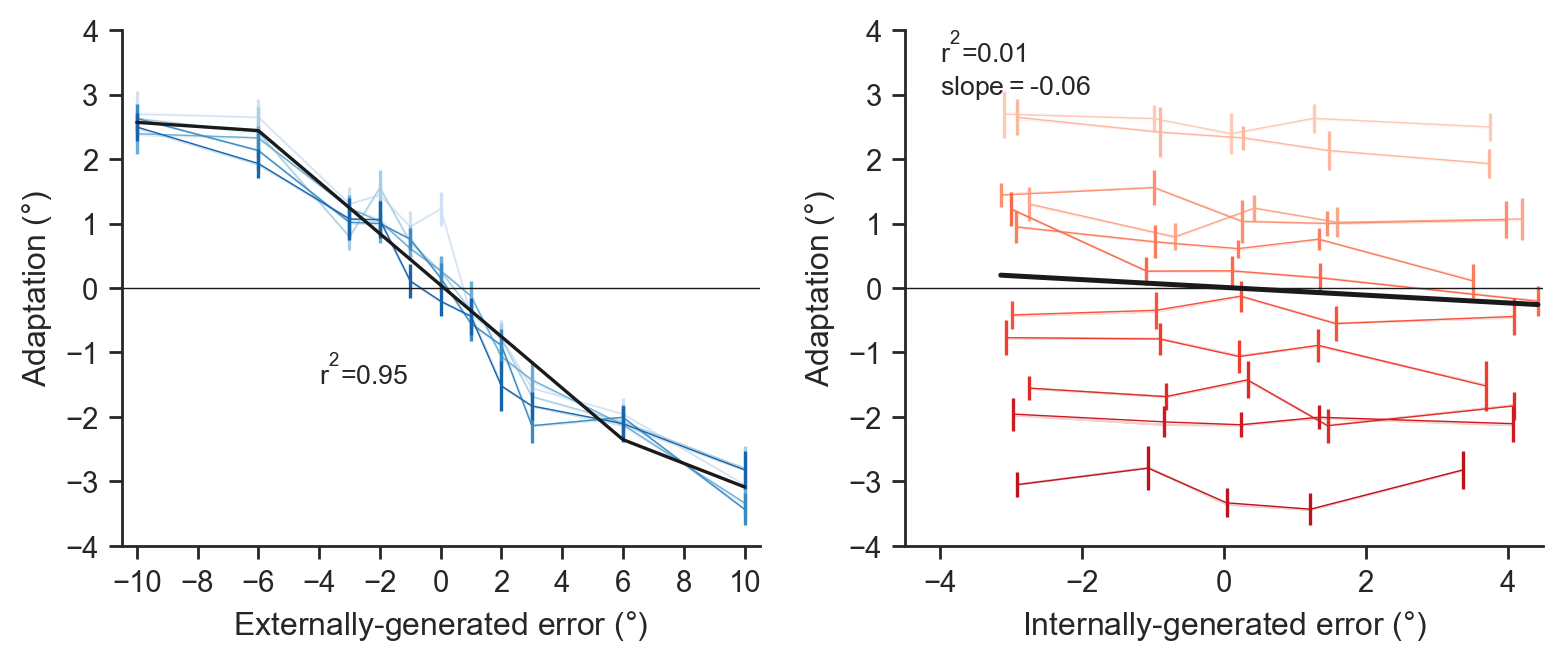

In [14]:
# Plot binned data
fig_rotation, y_fit, y_true, y_hat = plot_binned_data(rotation_binned, popn_rotation, "rotation", "beta_rotation_ege", "beta_rotation_ige")
fig_rotation.savefig("../figs/binned-adaptation.pdf")


In [15]:
# Compute r2 for breakpoint regression on binned data
vals_to_find_a = np.unique(popn_rotation["rotation"])
indices_a = np.searchsorted(x_fit, vals_to_find_a)
y_hat_a = np.repeat(y_fit[indices_a], 5)  # repeat 5 times bc there are 5 vals at each pert level
y_true_a = popn_rotation["adaptation"]

n = len(y_true_a) # Number of observations
p = 5          # Number of independent variables 

# Calculate the standard R-squared
r2 = r2_score(y_true_a, y_hat_a)

# Calculate the adjusted R-squared
adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print(f"R-squared: {r2}")
print(f"Adjusted R-squared: {adjusted_r2}")

R-squared: 0.9560252051587619
Adjusted R-squared: 0.9515379811953703


In [16]:
# Median RTs
temporal = df.groupby("SN")[["RT", "MT"]].median().reset_index()
print(temporal)
print(temporal["RT"].apply([np.mean, np.std]))
print(temporal["MT"].apply([np.mean, np.std]))

    SN        RT        MT
0    1  0.217744  0.343620
1    2  0.287679  0.371601
2    3  0.239722  0.431468
3    4  0.229688  0.395556
4    5  0.180490  0.391014
5    6  0.229735  0.351577
6    7  0.199726  0.455523
7    8  0.297683  0.359618
8    9  0.215667  0.354774
9   10  0.271949  0.391559
10  11  0.327623  0.395561
11  12  0.337393  0.367589
12  13  0.179794  0.315646
13  14  0.336224  0.466477
14  15  0.137841  0.327645
15  16  0.174712  0.387556
mean    0.241479
std     0.060101
Name: RT, dtype: float64
mean    0.381674
std     0.040982
Name: MT, dtype: float64


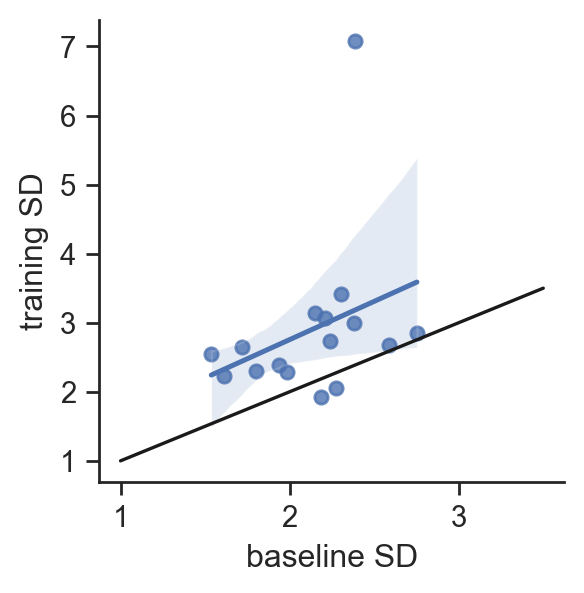

In [17]:
# Check if motor variability increases during perturbation block
var = pd.DataFrame({
    "sigma_motor_bsl":sigma_motor_bsl, 
    "sigma_motor_train":sigma_motor_train, 
    "sigma_v_train":sigma_v_train
})

fig, ax = plt.subplots(figsize=(3, 3))
ax.plot([1, 3.5], [1, 3.5], "k")
sns.regplot(data=var, x=sigma_motor_bsl, y=sigma_motor_train, ax=ax)
ax.set(xlabel="baseline SD", ylabel="training SD")
sns.despine()
plt.show()

---
## Statistics

In [18]:
# Baseline motor variability
res = bootstrap((df["motor_sd"].unique(),), np.mean, method="percentile")
print(f"Mean and 95% CI of baseline motor variability: {df.motor_sd.mean()},{[res.confidence_interval]}")

# Beta_EGE for EGEs of -6:6 only (bivariate)
res = bootstrap((beta_ege_6ege_uni,), np.mean, method="percentile")
print(f"Mean and 95% CI of univariate regression of [-6, 6] data: {beta_ege_6ege_uni.mean()},{res.confidence_interval}")

# Beta_EGE for all data (univariate)
res = bootstrap((beta_ege_all_uni,), np.mean, method="percentile")
print(f"Mean and 95% CI of univariate regression of all data: {beta_ege_all_uni.mean()},{res.confidence_interval}")

# Beta_EGE for EGEs of -6:+6 (univariate)
res = stats.ttest_rel(beta_ege_6ege_uni, beta_ege_all_uni)
print(f"Difference in slopes between [-6, 6] and all data: {res}")

# Beta_EGE for data only including EGEs of -1:+1 (bivariate)
res = bootstrap((beta_ege_1ege_bi,), np.mean, method="percentile")
print(f"Mean and 95% CI of EGE betas for 1deg data: {beta_ege_1ege_bi.mean()},{[res.confidence_interval]}")

# Beta_IGE for data only including EGEs of -1:+1 (bivariate)
res = bootstrap((beta_ige_1ege_bi,), np.mean, method="percentile")
print(f"Mean and 95% CI of IGE betas for 1deg data: {beta_ige_1ege_bi.mean()},{res.confidence_interval}")

# t-test against 0 for 1 deg Bivariate regression
res = stats.ttest_1samp(beta_ege_1ege_bi, popmean=0)
print(f"EGE betas for 1deg data versus Zero: {res}")

# t-test against 0 for 1 deg Bivariate regression
res = stats.ttest_1samp(beta_ige_1ege_bi, popmean=0)
print(f"IGE betas for 1deg data versus Zero: {res}")

# Beta_EGE for EGEs of -1:+1 (univariate)
res = bootstrap((beta_ege_1ege_uni,), np.mean, method="percentile")
print(f"Mean and 95% CI of univariate regression of EGEs from -1:+1: {beta_ege_1ege_uni.mean()},{res.confidence_interval}")

# Beta_IGE for IGEs of -1:+1 (univariate)
res = bootstrap((beta_ige_1ige_uni,), np.mean, method="percentile")
print(f"Mean and 95% CI of univariate regression of IGEs from -1:+1: {beta_ige_1ige_uni.mean()},{res.confidence_interval}")

Mean and 95% CI of baseline motor variability: 2.047790741595615,[ConfidenceInterval(low=1.9031894955916038, high=2.178818879290305)]
Mean and 95% CI of univariate regression of [-6, 6] data: -0.39858214808702297,ConfidenceInterval(low=-0.44355732888044314, high=-0.35317715500386143)
Mean and 95% CI of univariate regression of all data: -0.3216493297703189,ConfidenceInterval(low=-0.3524181687654844, high=-0.29017872878726425)
Difference in slopes between [-6, 6] and all data: TtestResult(statistic=-7.561687987547446, pvalue=1.7114233056661486e-06, df=15)
Mean and 95% CI of EGE betas for 1deg data: -0.49846108534988787,[ConfidenceInterval(low=-0.5968048976973096, high=-0.4000851390463445)]
Mean and 95% CI of IGE betas for 1deg data: -0.06864798452256746,ConfidenceInterval(low=-0.127881967207678, high=-0.009617575461579363)
EGE betas for 1deg data versus Zero: TtestResult(statistic=-9.648543209889674, pvalue=7.984140957679419e-08, df=15)
IGE betas for 1deg data versus Zero: TtestResult(s